# Iris Classification: Logistic Regression vs Decision Tree
**Goal:** Supervised classification on the Iris dataset with feature scaling, an 80/20 train/test split, two models, and benchmarking by accuracy, precision, recall and F1-score.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

%matplotlib inline
sns.set_style("whitegrid")

## 2. Load the dataset
Change the path below if your CSV is in a different folder.

In [ ]:
df = pd.read_csv("1794206110138_iris.csv") 
print("Shape:", df.shape)
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(df.info())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass distribution:\n", df["species"].value_counts())
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB
None

Missing values: 0

Class distribution:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory Data Analysis (pairplot)

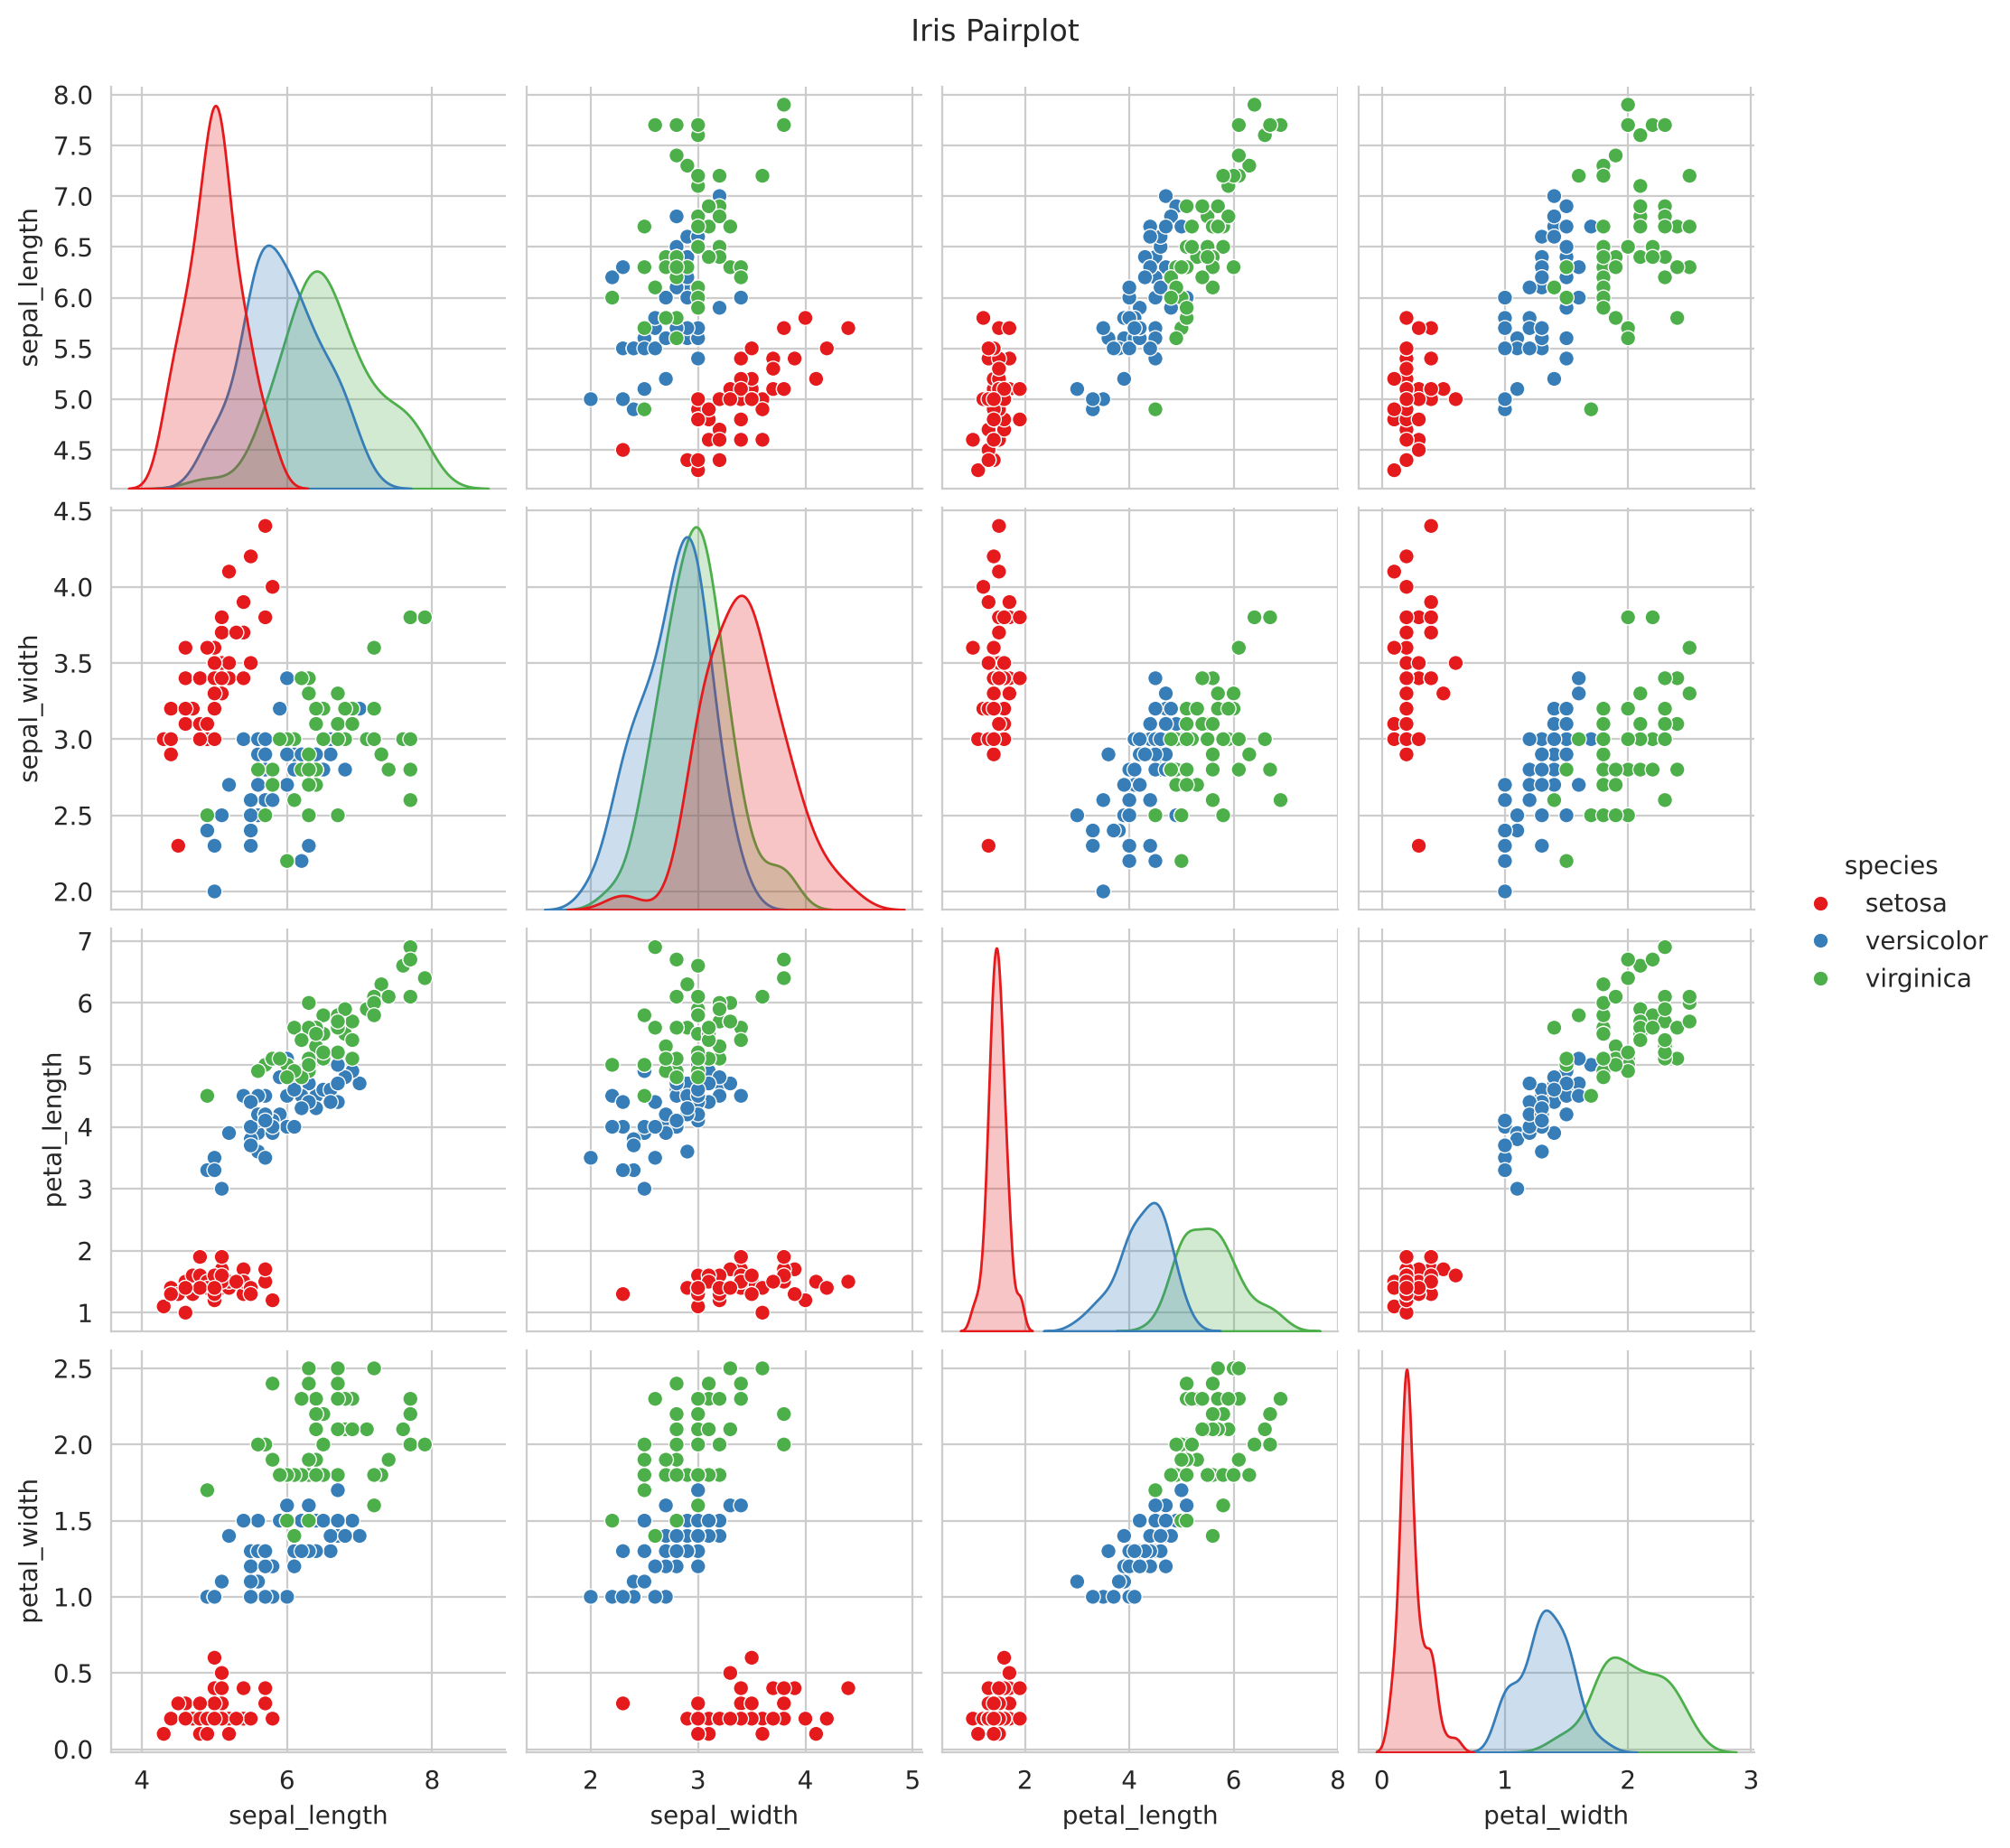

In [4]:
sns.pairplot(df, hue="species", diag_kind="kde", palette="Set1")
plt.suptitle("Iris Pairplot", y=1.02)
plt.show()

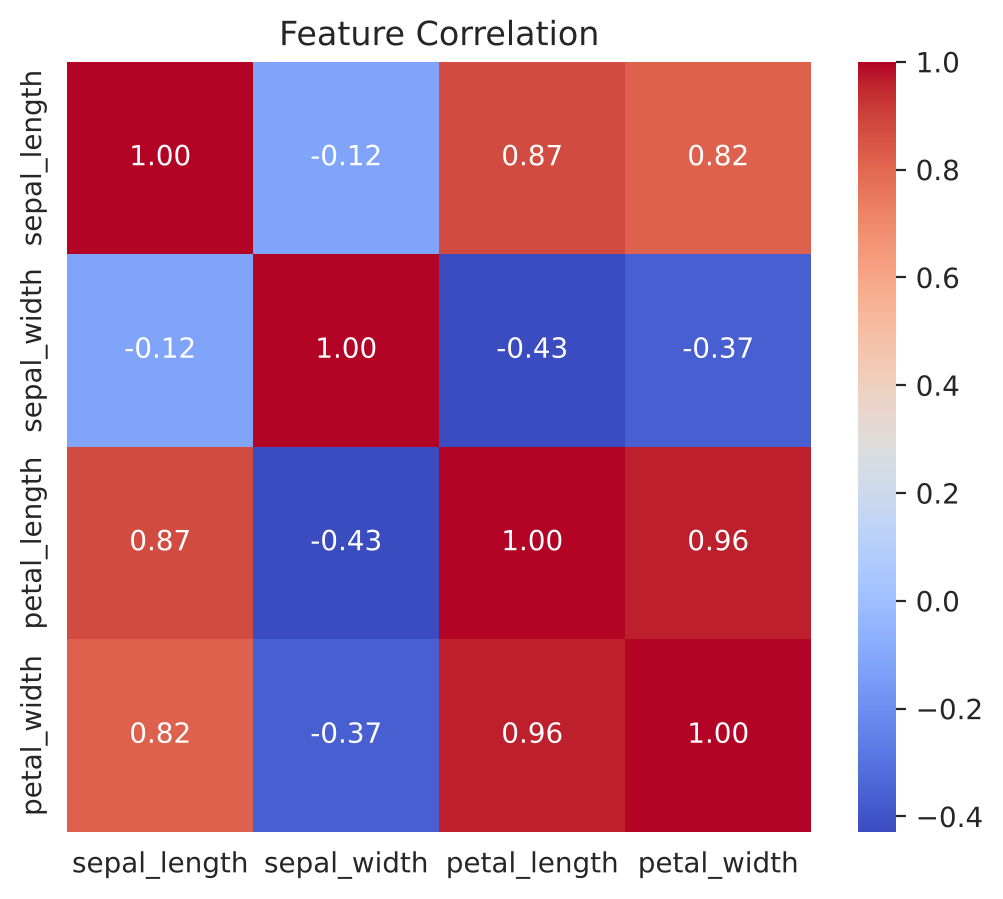

In [5]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.drop(columns="species").corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation")
plt.show()

## 4. Prepare data: encode labels, split 80/20, scale

In [6]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[features].values

le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = le.classes_
print("Classes:", dict(zip(class_names, range(len(class_names)))))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Fit the scaler on TRAIN only, then apply to TEST (avoids data leakage)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Scaled train mean ~", X_train_s.mean(axis=0).round(2))
print("Scaled train std  ~", X_train_s.std(axis=0).round(2))

Classes: {'setosa': 0, 'versicolor': 1, 'virginica': 2}
Train: (120, 4)  Test: (30, 4)
Scaled train mean ~ [-0. -0.  0.  0.]
Scaled train std  ~ [1. 1. 1. 1.]


## 5. Train the models

In [7]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
dtree = DecisionTreeClassifier(max_depth=3, random_state=42)

log_reg.fit(X_train_s, y_train)
dtree.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": dtree}
preds = {name: m.predict(X_test_s) for name, m in models.items()}
print("Models trained.")

Models trained.


## 6. Evaluate: accuracy, precision, recall, F1

In [8]:
rows = []
for name, pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy":  accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, average="weighted"),
        "Recall":    recall_score(y_test, pred, average="weighted"),
        "F1-score":  f1_score(y_test, pred, average="weighted"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


In [9]:
for name, pred in preds.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=class_names))

=== Logistic Regression ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

=== Decision Tree ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



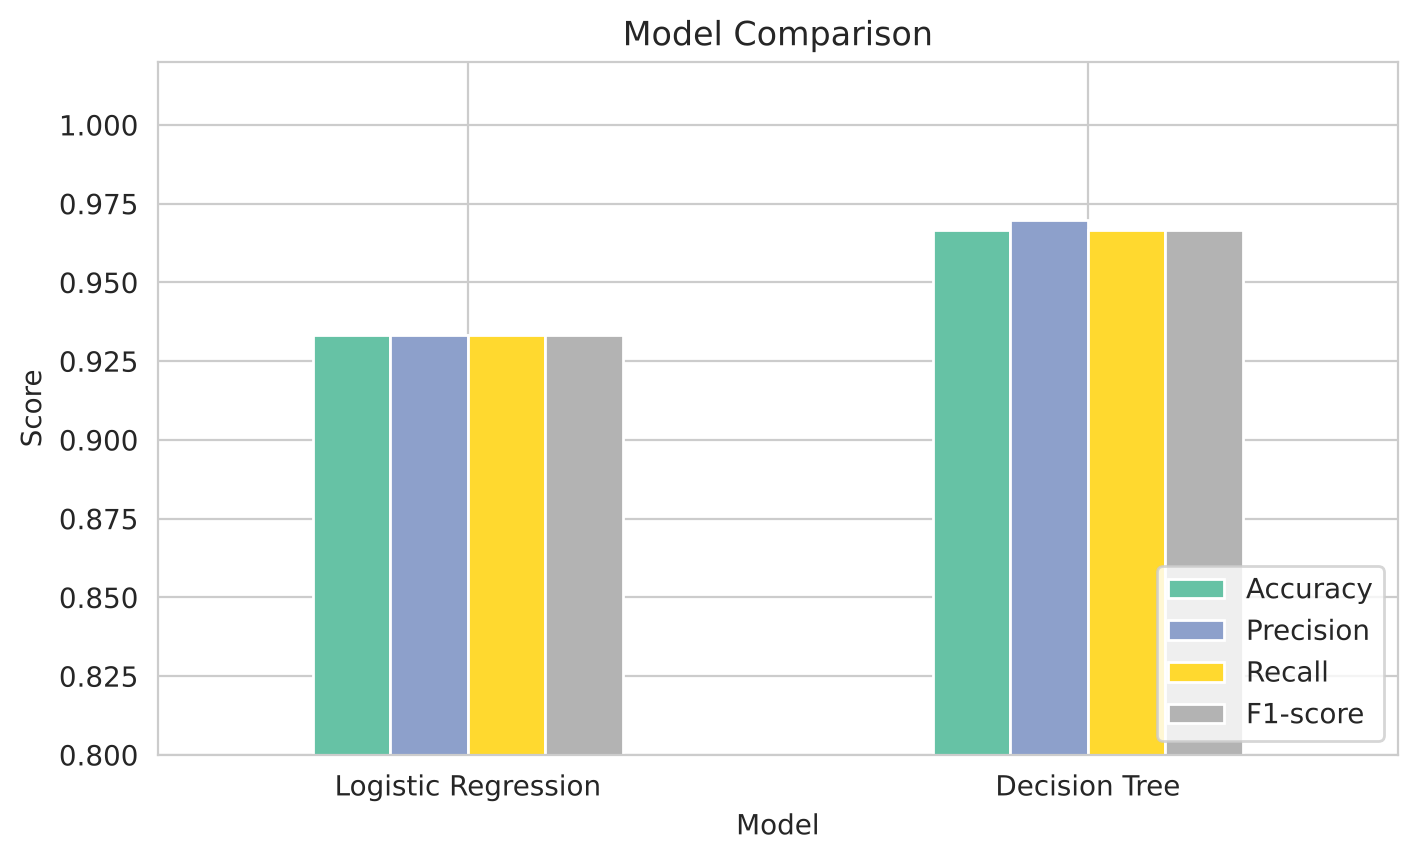

In [10]:
results.plot(kind="bar", figsize=(8, 4.5), ylim=(0.8, 1.02), rot=0, colormap="Set2")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.legend(loc="lower right")
plt.show()

## 7. Confusion matrix heatmaps

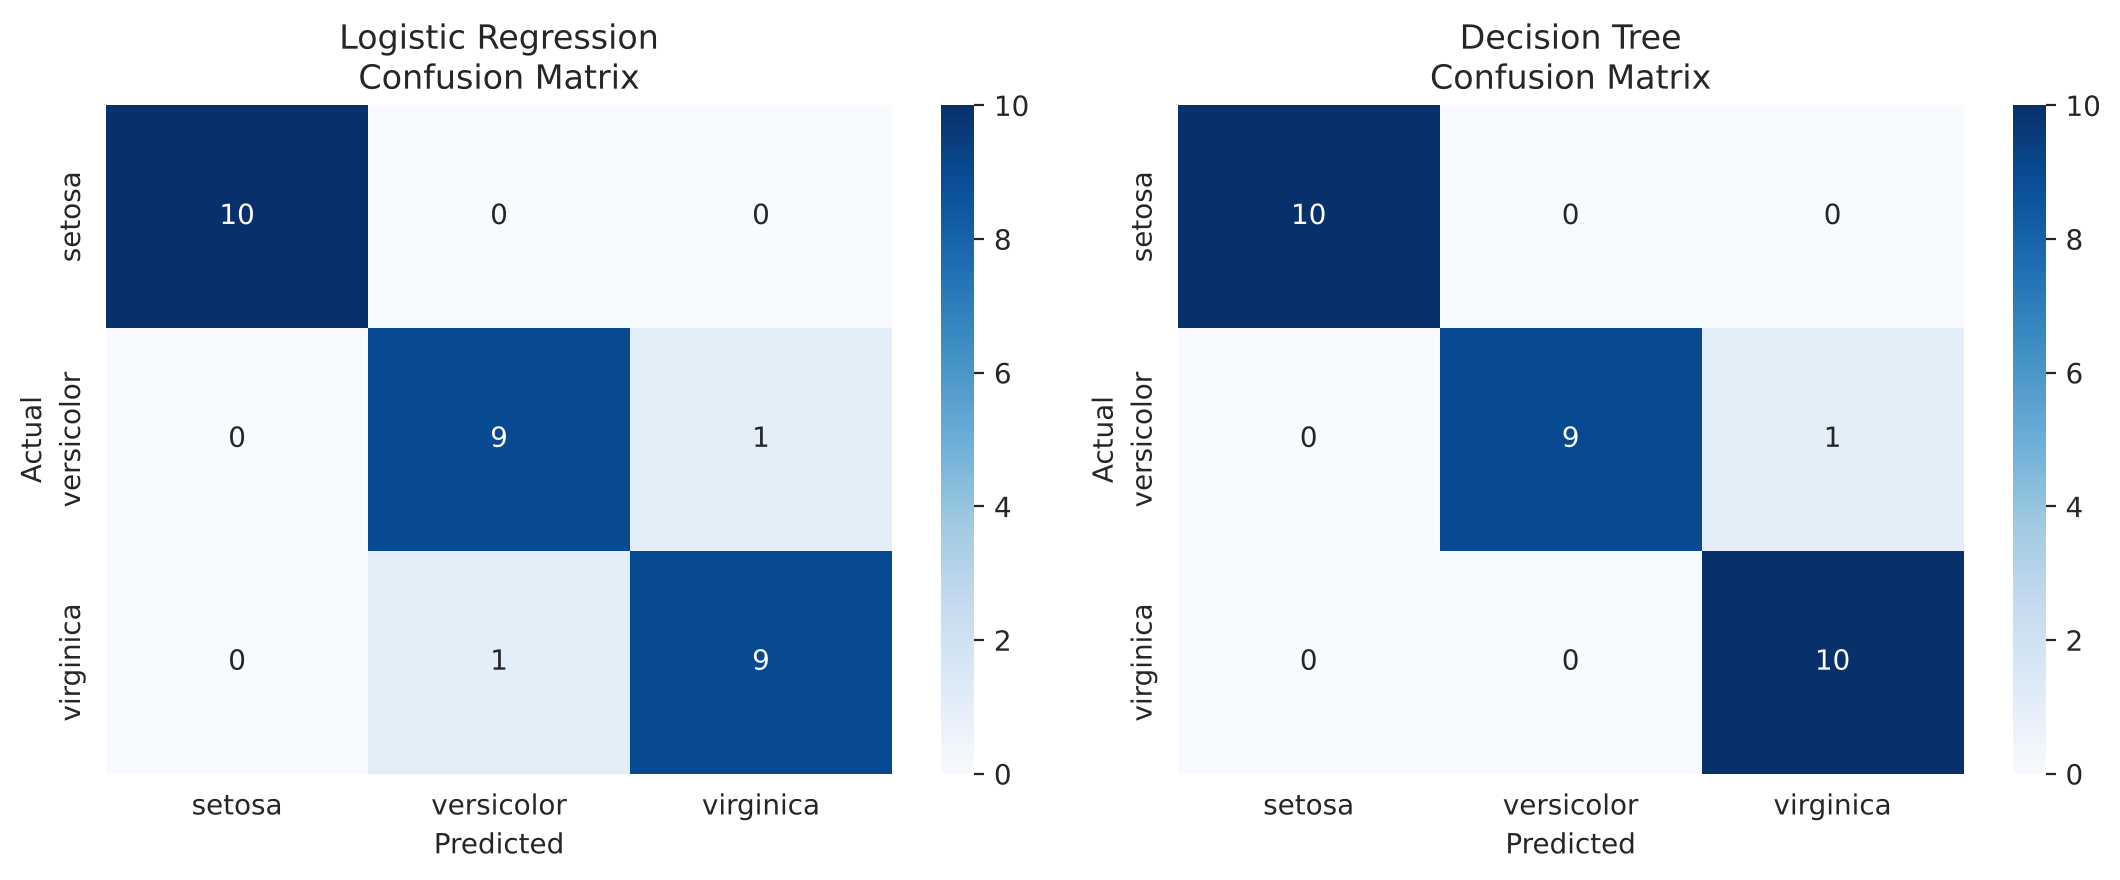

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{name}\nConfusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 8. Decision boundary visualization
A decision boundary can only be drawn in 2D, so both models are re-trained on **petal length** and **petal width** (the two most informative features) just for this plot.

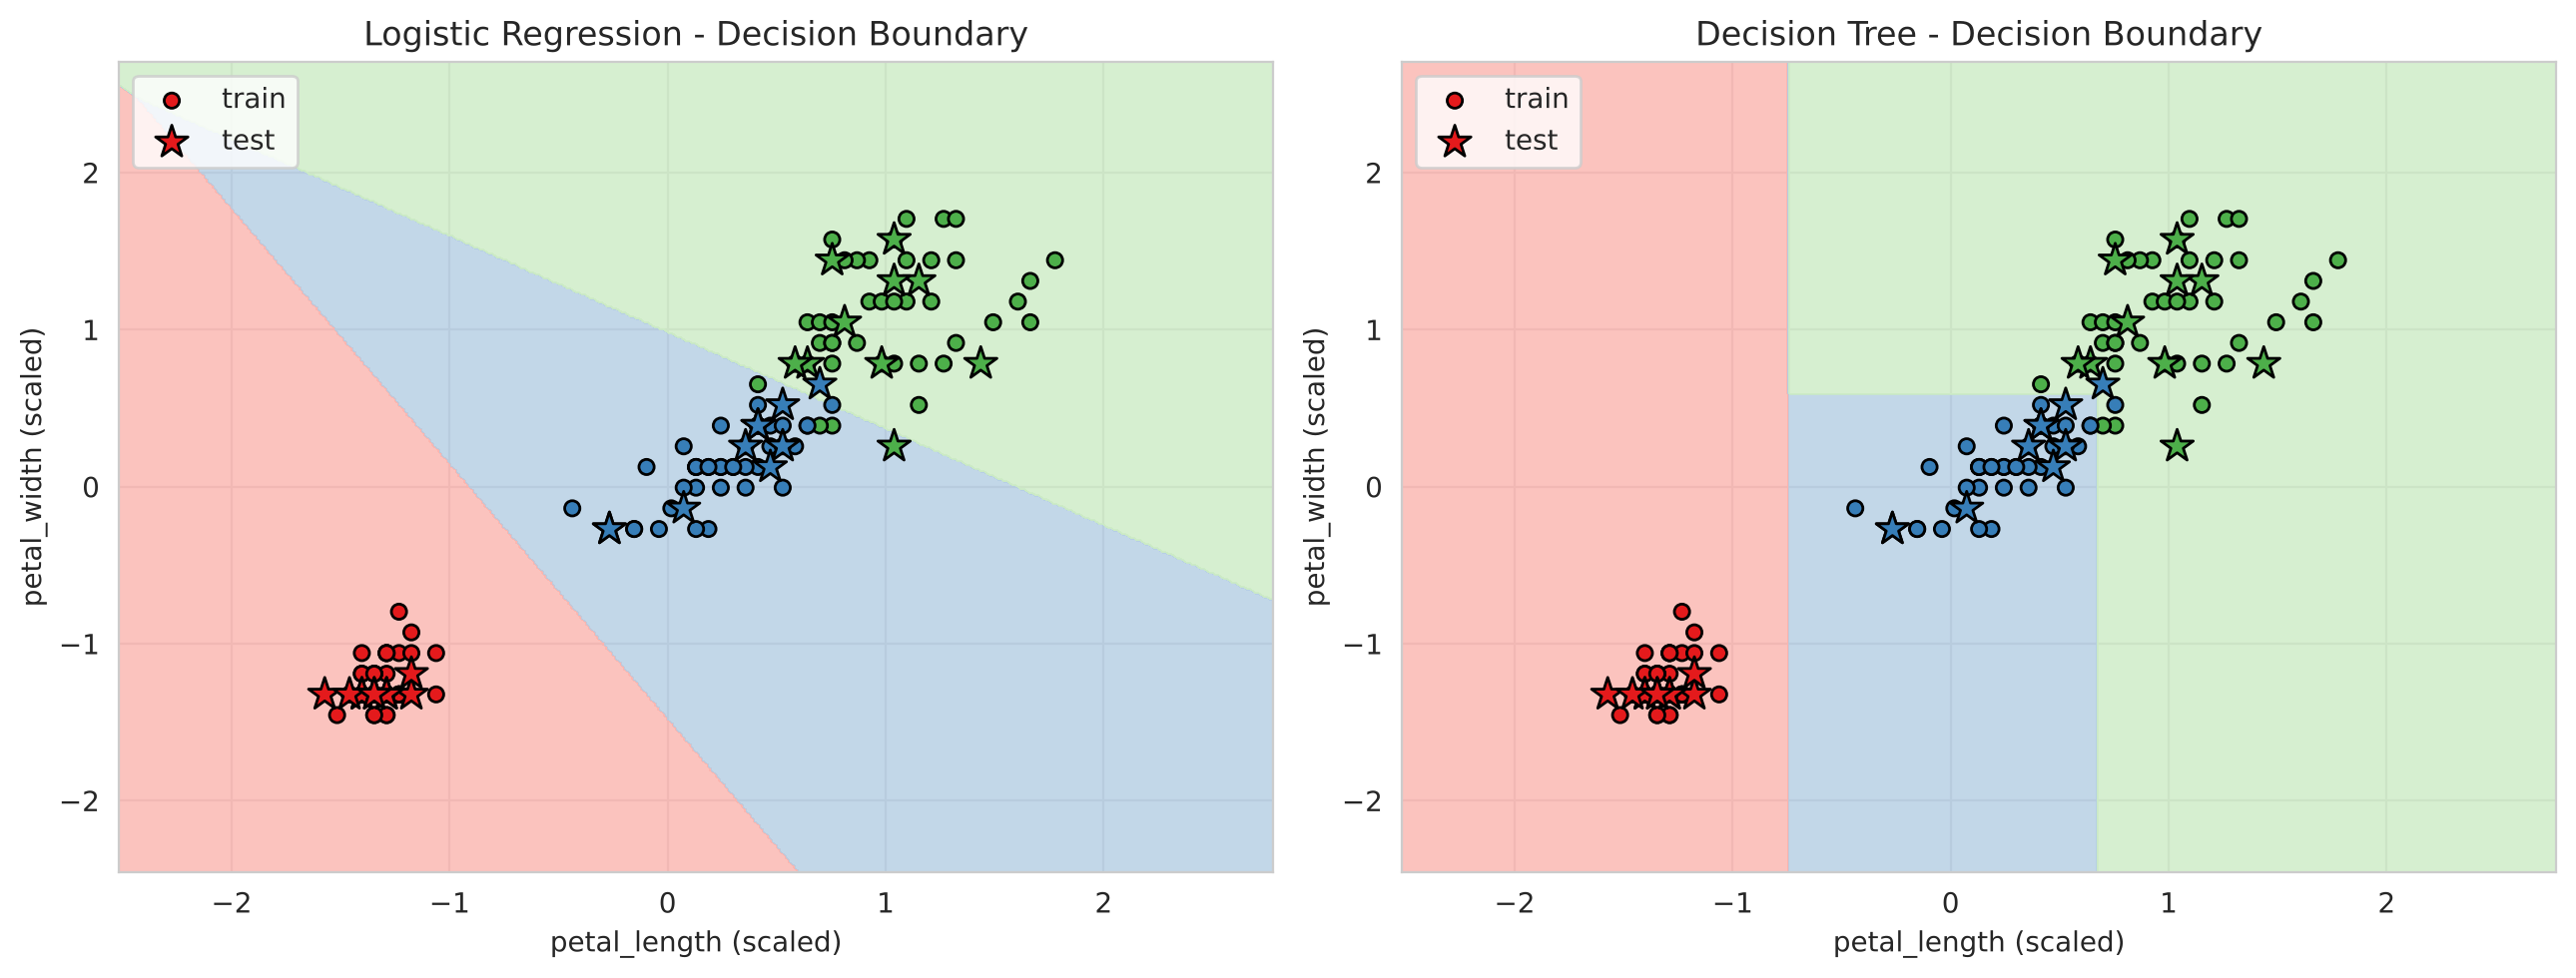

Class colours: {'setosa': 'red', 'versicolor': 'blue', 'virginica': 'green'}


In [12]:
cols = [features.index("petal_length"), features.index("petal_width")]
Xtr2, Xte2 = X_train_s[:, cols], X_test_s[:, cols]

xx, yy = np.meshgrid(
    np.linspace(Xtr2[:, 0].min() - 1, Xtr2[:, 0].max() + 1, 400),
    np.linspace(Xtr2[:, 1].min() - 1, Xtr2[:, 1].max() + 1, 400),
)
cmap_bg = matplotlib.colors.ListedColormap(["#fbb4ae", "#b3cde3", "#ccebc5"])
cmap_pt = matplotlib.colors.ListedColormap(["#e41a1c", "#377eb8", "#4daf4a"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, model) in zip(axes, models.items()):
    m2 = type(model)(**model.get_params()).fit(Xtr2, y_train)
    Z = m2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
    ax.scatter(Xtr2[:, 0], Xtr2[:, 1], c=y_train, cmap=cmap_pt,
               edgecolor="k", s=30, label="train")
    ax.scatter(Xte2[:, 0], Xte2[:, 1], c=y_test, cmap=cmap_pt,
               edgecolor="k", marker="*", s=150, label="test")
    ax.set_title(f"{name} - Decision Boundary")
    ax.set_xlabel("petal_length (scaled)")
    ax.set_ylabel("petal_width (scaled)")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()
print("Class colours:", dict(zip(class_names, ["red", "blue", "green"])))

## 9. (Bonus) Decision tree structure

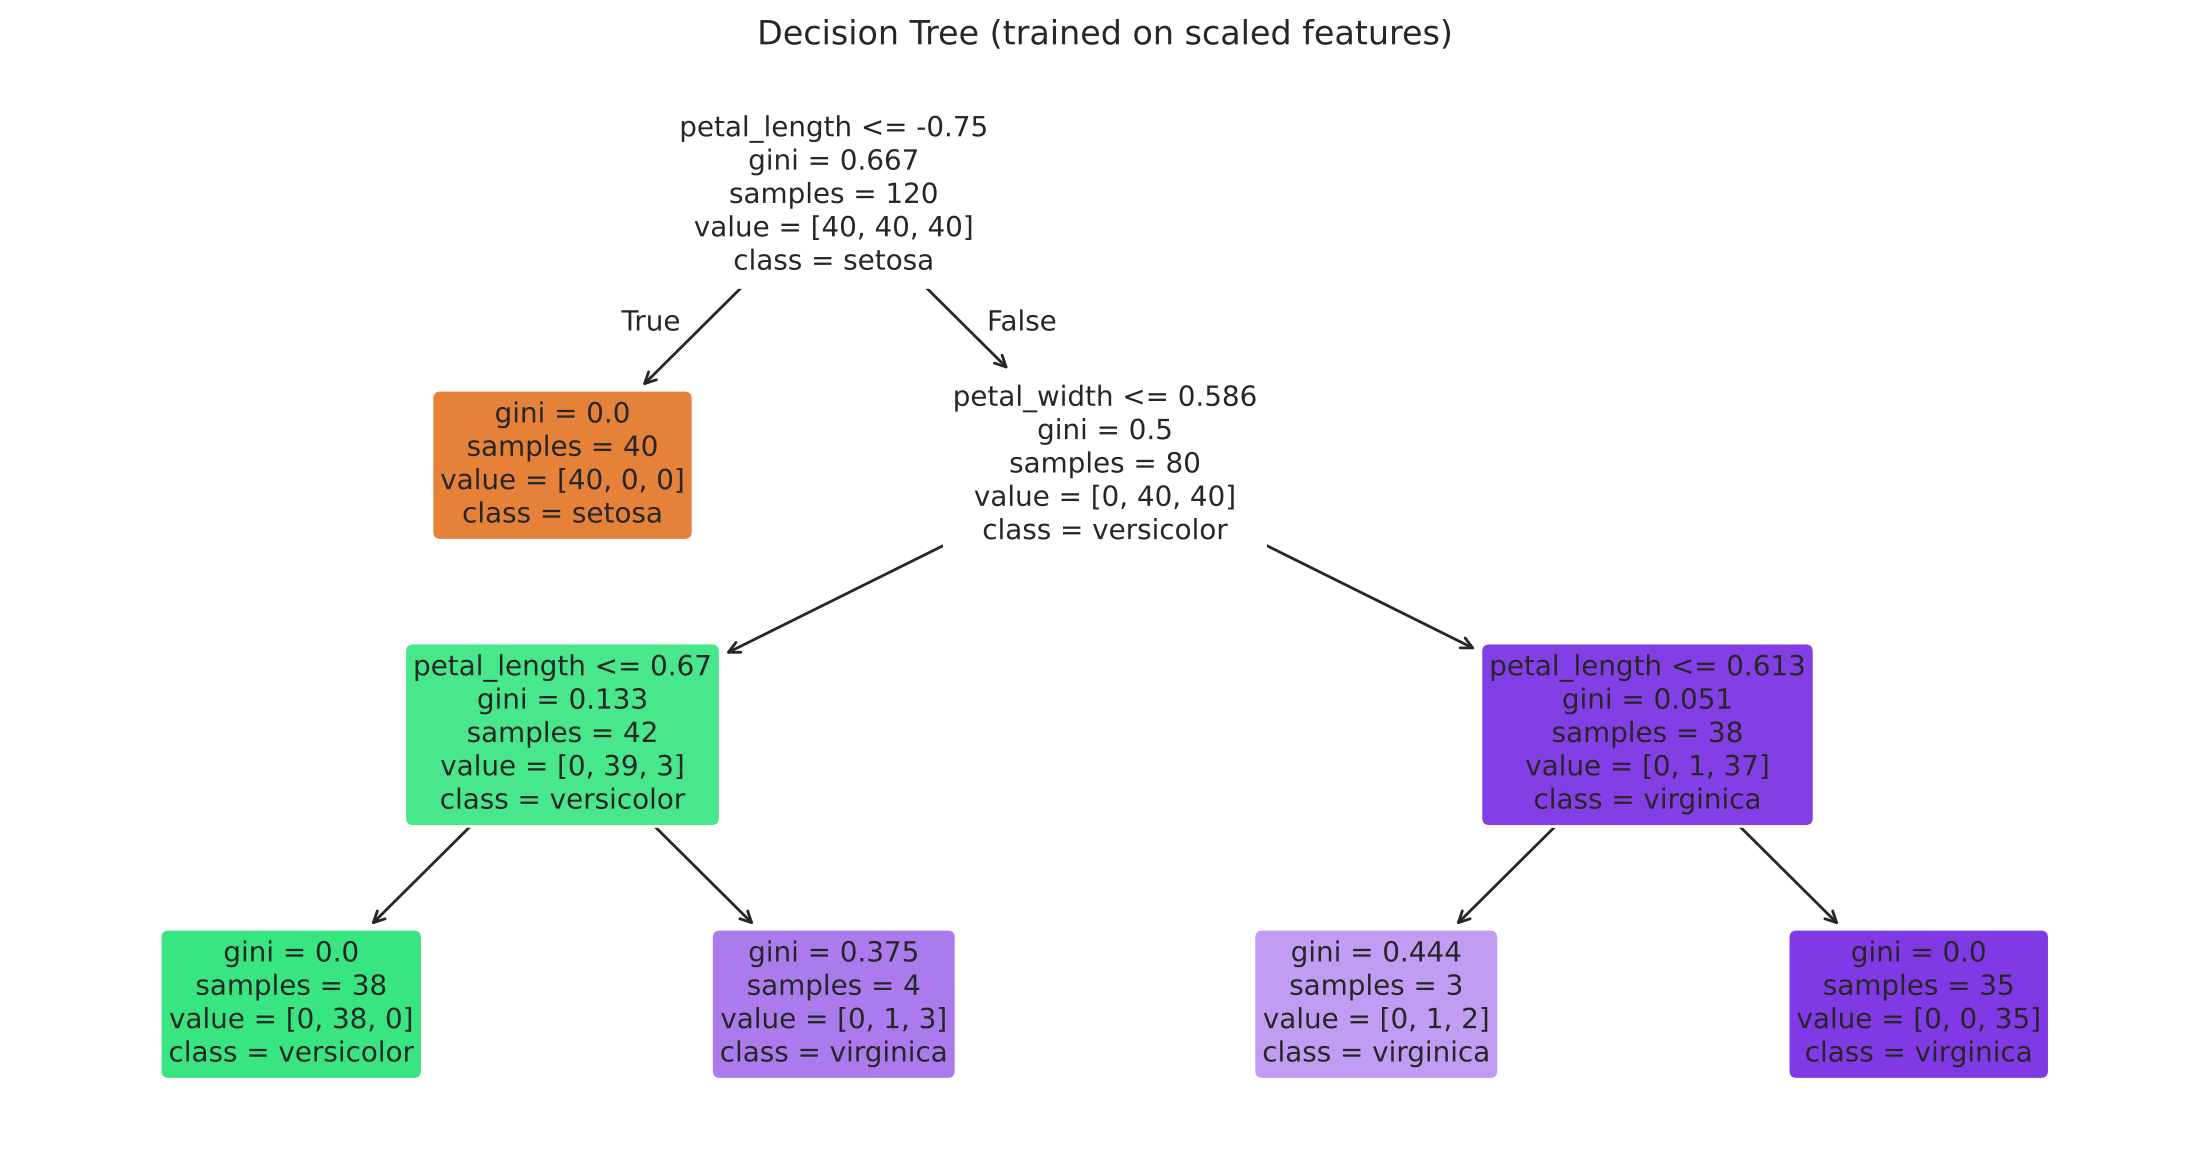

In [13]:
plt.figure(figsize=(14, 7))
plot_tree(dtree, feature_names=features, class_names=list(class_names),
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree (trained on scaled features)")
plt.show()

## 10. Conclusion
- **Setosa** is perfectly separable; both models classify it with no errors.
- Errors occur only between **versicolor** and **virginica**, whose feature ranges overlap.
- The Decision Tree edged out Logistic Regression on this split, but the test set has only 30 samples, so one flower changes accuracy by 3.3%. Use cross-validation for a more reliable comparison.